
# Hälsostudie – Del 1
## Grundläggande analys och statistik

**Kurs:** Pythonprogrammering och statistisk dataanalys

**Författare:** Vafa Nasirova

## 1. Introduktion

I denna rapport analyseras hälsodata från 800 deltagare.
Datasetet innehåller information om ålder, kön, längd, vikt,
blodtryck, kolesterolnivå, rökvanor och sjukdomsstatus.

Analysen genomförs i Python med hjälp av beskrivande statistik,
visualiseringar, simuleringar, konfidensintervall och hypotesprövning.

### Frågeställningar

- Hur ser fördelningen av deltagarnas hälsovariabler ut?
- Hur stor andel av deltagarna har sjukdomen?
- Hur kan populationens genomsnittliga systoliska blodtryck skattas?
- Har rökare högre genomsnittligt systoliskt blodtryck än icke-rökare?
- Hur stor är hypotestestets statistiska styrka vid olika effektstorlekar?


In [1]:
# Importera nödvändiga bibliotek

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


## 2. Datainläsning och datakvalitet

Innan analysen påbörjas kontrolleras datatyper,
saknade värden, dubbletter och kategoriska variabler.

### 2.1 Inläsning av dataset


In [2]:
# Läs in datasetet

df = pd.read_csv("../data/health_study_dataset.csv")

# Visa de fem första observationerna

df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0



### 2.2 Undersökning av datasetets struktur

Här undersöks datasetets storlek och variablernas datatyper.


In [3]:
# Undersök antalet rader och kolumner

print(f"Antal observationer: {df.shape[0]}")
print(f"Antal kolumner: {df.shape[1]}")

Antal observationer: 800
Antal kolumner: 9


In [4]:
# Undersök datasetets struktur och datatyper

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [5]:
# Kontrollera antalet saknade värden per variabel

df.isnull().sum()

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

In [6]:
# Kontrollera förekomsten av duplicerade rader

print(f"Antal duplicerade rader: {df.duplicated().sum()}")

# Kontrollera om deltagarnas ID är unika

print(f"Antal duplicerade ID: {df['id'].duplicated().sum()}")

Antal duplicerade rader: 0
Antal duplicerade ID: 0


In [7]:
# Undersök vilka värden de kategoriska variablerna innehåller

for col in ["sex", "smoker", "disease"]:
    print(f"{col}: {df[col].unique()}")

sex: <StringArray>
['F', 'M']
Length: 2, dtype: str
smoker: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
disease: [0 1]



### 2.3 Sammanfattning av datakvaliteten

Datasetet består av 800 observationer och 9 variabler.
Inga saknade värden, duplicerade rader eller duplicerade ID
har identifierats. De kategoriska variablerna innehåller
endast förväntade kategorier.

Ingen rensning behövs med anledning av dessa kontroller.



## 3. Beskrivande statistik

Medelvärde, median, standardavvikelse, minimum och maximum
beräknas för de fem kvantitativa hälsovariablerna.

Medelvärde och median beskriver variablernas centrala läge,
medan standardavvikelse, minimum och maximum ger information
om spridningen.


In [8]:
# Välj de kvantitativa variabler som ska analyseras

numerical_cols = [
    "age",
    "weight",
    "height",
    "systolic_bp",
    "cholesterol"
]

# Beräkna beskrivande statistik
descriptive_stats = df[numerical_cols].agg(
    ["mean", "median", "std", "min", "max"]
)


descriptive_stats.round(2)

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
std,14.50,13.69,9.80,12.79,0.85
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


In [9]:
# Transponera tabellen och ange svenska rubriker

summary = descriptive_stats.T

summary.columns = [
    "Medelvärde",
    "Median",
    "Standardavvikelse",
    "Minimum",
    "Maximum"
]
summary.index = [
    "Ålder (år)",
    "Vikt (kg)",
    "Längd (cm)",
    "Systoliskt blodtryck (mmHg)",
    "Kolesterol (mmol/L)"
]

summary.round(2)

,Medelvärde,Median,Standardavvikelse,Minimum,Maximum
Ålder (år),49.43,50.00,14.50,18.0,90.00
Vikt (kg),73.41,73.20,13.69,33.7,114.40
Längd (cm),171.85,171.35,9.80,144.4,200.40
Systoliskt blodtryck (mmHg),149.18,149.40,12.79,106.8,185.90
Kolesterol (mmol/L),4.93,4.97,0.85,2.5,7.88


**Tabell 1.** Beskrivande statistik i form av medelvärde, median, standardavvikelse, minimum och maximum för deltagarnas ålder, vikt, längd, systoliska blodtryck och kolesterolnivå.


### 3.1 Tolkning av beskrivande statistik

Deltagarnas genomsnittliga ålder är 49,43 år.
Åldersspannet är relativt stort, från 18 till 90 år.

Medelvärde och median ligger nära varandra för samtliga
analyserade variabler. Det kan tyda på relativt symmetriska
fördelningar, men räcker inte för att dra en sådan slutsats.

Det systoliska blodtrycket har ett medelvärde på 149,18 mmHg
och en standardavvikelse på 12,79 mmHg. Blodtrycket är
särskilt intressant i denna studie eftersom det ligger
till grund för den fortsatta statistiska analysen.

Eftersom variablerna har olika måttenheter är det inte
lämpligt att jämföra deras standardavvikelser direkt.



## 4. Visualiseringar

### 4.1 Fördelning av systoliskt blodtryck

Blodtryckets fördelning undersöks med ett histogram för
att få en uppfattning om fördelningens form och spridning.


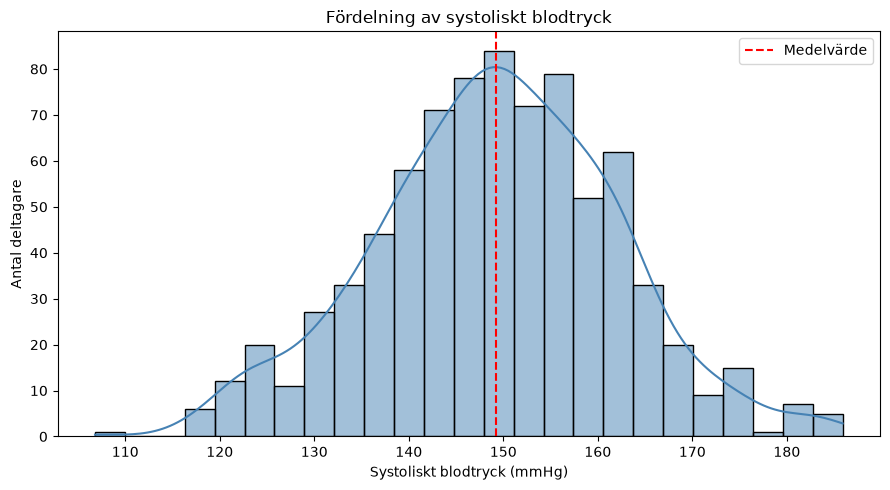

In [10]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="systolic_bp",
    bins=25,
    kde=True,
    color="steelblue"
)

plt.axvline(
    df["systolic_bp"].mean(),
    color="red",
    linestyle="--",
    label="Medelvärde"
)

plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Systoliskt blodtryck (mmHg)")
plt.ylabel("Antal deltagare")
plt.legend()
plt.tight_layout()
plt.show()


**Figur 1.** Fördelning av systoliskt blodtryck.
Den blå kurvan visar den skattade tätheten och den
röda streckade linjen markerar medelvärdet.



#### Tolkning

Fördelningen är ungefär symmetrisk och klockformad.
De flesta observationerna ligger mellan 130 och 170 mmHg.

Medelvärdet (149,18 mmHg) ligger nära medianen
(149,40 mmHg). Histogrammet antyder en ungefärlig
normalfördelning, men detta kan inte fastställas
enbart genom en visuell bedömning.



### 4.2 Viktfördelning per kön

Ett lådagram används för att jämföra viktens median
och spridning mellan kvinnor och män.


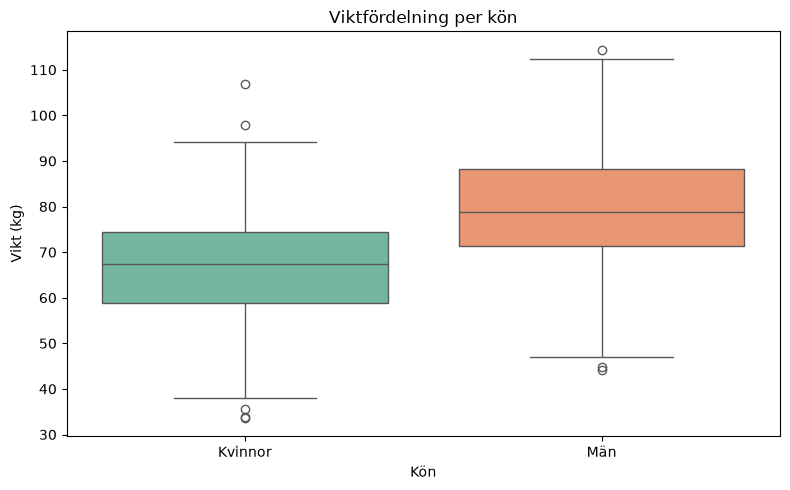

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="sex",
    y="weight",
    hue="sex",
    palette="Set2",
    legend=False,
    order=["F", "M"]
)

plt.title("Viktfördelning per kön")
plt.xlabel("Kön")
plt.ylabel("Vikt (kg)")
plt.xticks([0, 1], ["Kvinnor", "Män"])
plt.tight_layout()
plt.show()


**Figur 2.** Viktfördelning bland kvinnor och män.
Lådorna visar kvartilavståndet, linjerna inuti lådorna
visar medianen och punkterna markerar avvikande värden.


#### Tolkning av viktfördelningen per kön

Medianvikten är cirka 67 kg för kvinnor och 79 kg
för män, vilket innebär en skillnad på ungefär 12 kg.

De mittersta 50 % av observationerna ligger mellan
59 och 74 kg för kvinnor och mellan 71 och 88 kg för män.
Spridningen inom grupperna är därmed relativt likartad.

Avvikande värden förekommer i båda grupperna, men
dessa behöver inte vara felaktiga observationer.

Skillnaden mellan grupperna är tydlig i diagrammet,
men dess statistiska signifikans har inte undersökts.



### 4.3 Fördelning av rökvanor

Eftersom rökvanor är en kategorisk variabel används
ett stapeldiagram för att visa gruppernas relativa frekvenser.


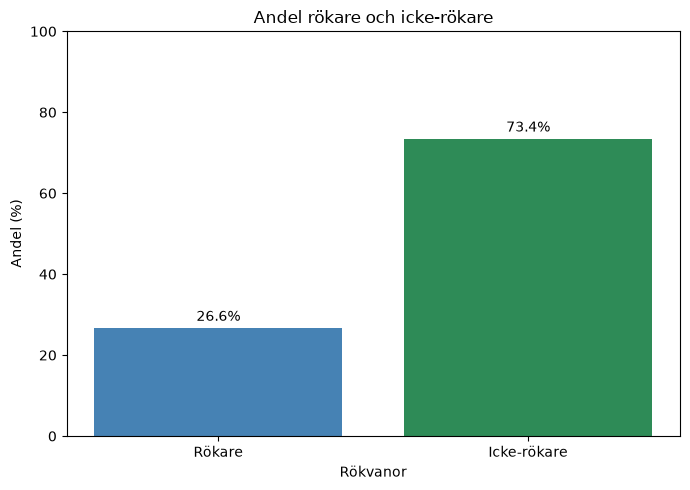

In [12]:
# Beräkna relativa frekvenser i procent

smoker_percentage = (
    df["smoker"].value_counts(normalize=True) * 100
)

smoker_percentage = smoker_percentage.reindex(["Yes", "No"])

# Skapa stapeldiagram

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Rökare", "Icke-rökare"],
    smoker_percentage,
    color=["steelblue", "seagreen"]
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.title("Andel rökare och icke-rökare")
plt.xlabel("Rökvanor")
plt.ylabel("Andel (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


**Figur 3.** Andel rökare och icke-rökare i datasetet.


#### Tolkning av stapeldiagrammet


Av deltagarna är 26,6 % rökare och 73,4 % icke-rökare.

Gruppen icke-rökare är alltså betydligt större.
De olika gruppstorlekarna är relevanta för den
kommande hypotesprövningen och poweranalysen.




## 5. Simulering av sjukdomsförekomst

Variabeln `disease` är binär och antar värdet 1 vid
sjukdom och 0 annars. Sjukdomsstatus kan därför
modelleras som ett Bernoulliförsök.

Den observerade sjukdomsandelen används som
sannolikhetsparameter vid simuleringen av 1 000 personer.

### 5.1 Observerad sjukdomsförekomst


In [13]:
# Beräkna antal deltagare och antal personer med sjukdomen

n = len(df)
n_disease = df["disease"].sum()

# Beräkna observerad sannolikhet för sjukdom

p = df["disease"].mean()

print(f"Antal deltagare: {n}")
print(f"Antal personer med sjukdomen: {n_disease}")
print(f"Observerad sjukdomsandel: {p:.2%}")

Antal deltagare: 800
Antal personer med sjukdomen: 47
Observerad sjukdomsandel: 5.88%



### 5.2 Simulering av sjukdomsstatus

Sjukdomsstatus simuleras för 1 000 oberoende individer
med sannolikheten p. Ett fast slumpfrö används för
att resultatet ska kunna reproduceras.


In [14]:
# Ange slumpfrö för reproducerbarhet

np.random.seed(42)

# Antal personer som ska simuleras

n_sim = 1000

# Simulera sjukdomsstatus

simulated_disease = np.random.binomial(
    n=1,
    p=p,
    size=n_sim
)

# Beräkna antal och andel med sjukdomen

simulated_count = simulated_disease.sum()
simulated_p = simulated_disease.mean()

print(f"Antal simulerade personer: {n_sim}")
print(f"Antal med sjukdomen: {simulated_count}")
print(f"Simulerad sjukdomsandel: {simulated_p:.2%}")

Antal simulerade personer: 1000
Antal med sjukdomen: 56
Simulerad sjukdomsandel: 5.60%


### 5.3 Jämförelse mellan observerad och simulerad andel


In [15]:
# Beräkna skillnaden i procentenheter

difference = (simulated_p - p) * 100

# Skapa jämförelsetabell

comparison = pd.DataFrame({
    "Datakälla": ["Observerad", "Simulerad"],
    "Antal personer": [n, n_sim],
    "Antal med sjukdomen": [n_disease, simulated_count],
    "Andel (%)": [p * 100, simulated_p * 100]
})

print(f"Skillnad: {difference:.2f} procentenheter")

comparison.round(2)

Skillnad: -0.27 procentenheter


,Datakälla,Antal personer,Antal med sjukdomen,Andel (%)
0,Observerad,800,47,5.88
1,Simulerad,1000,56,5.60


**Tabell 2.** Jämförelse mellan observerad och
simulerad sjukdomsförekomst.

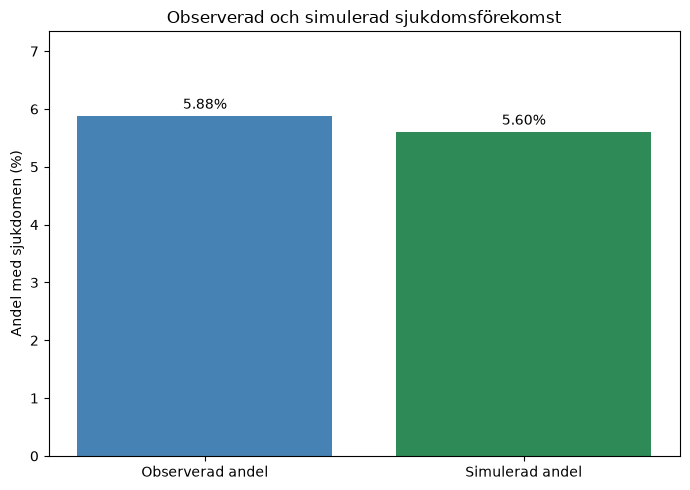

In [16]:
plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Observerad andel", "Simulerad andel"],
    [p * 100, simulated_p * 100],
    color=["steelblue", "seagreen"]
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.title("Observerad och simulerad sjukdomsförekomst")
plt.ylabel("Andel med sjukdomen (%)")
plt.ylim(0, max(p, simulated_p) * 100 * 1.25)
plt.tight_layout()
plt.show()

**Figur 4.** Jämförelse mellan observerad
sjukdomsandel i datasetet och simulerad sjukdomsandel
hos 1 000 individer.


### 5.4 Tolkning av simuleringsresultatet

Den observerade sjukdomsandelen är 5,88 %, jämfört
med den simulerade andelen på 5,60 %.

Den simulerade andelen är cirka 0,28 procentenheter
lägre. Skillnaden kan förklaras av slumpvariation.

Eftersom simuleringen använder den observerade andelen
som sannolikhetsparameter är det inte förvånande att
resultaten ligger nära varandra.

Simuleringen ger däremot ingen oberoende skattning
av sjukdomsandelen i populationen.



## 6. Konfidensintervall

Populationens genomsnittliga systoliska blodtryck
skattas med två metoder: normalapproximation och bootstrap.
Konfidensnivån är 95 % för båda metoderna.

### 6.1 Konfidensintervall med normalapproximation

Normalapproximationen motiveras av centrala
gränsvärdessatsen och den stora stickprovsstorleken
(n = 800), under antagandet om oberoende observationer.

Eftersom populationens standardavvikelse är okänd
används stickprovets standardavvikelse som skattning.


Det 95-procentiga konfidensintervallet beräknas enligt:

$$
\bar{x} \pm z_{1-\alpha/2}\frac{s}{\sqrt{n}}
$$

där:

- $\bar{x}$ = stickprovets medelvärde
- $s$ = stickprovets standardavvikelse
- $n$ = antal observationer
- $\alpha$ = signifikansnivå (0,05)
- $z_{1-\alpha/2}$ = kritiskt värde från standardnormalfördelningen

In [17]:
# Välj variabeln systoliskt blodtryck

bp = df["systolic_bp"].dropna()

# Beräkna nödvändiga statistiska mått

n_bp = len(bp)
mean_bp = bp.mean()
std_bp = bp.std(ddof=1)

# Beräkna standardfelet

se_bp = std_bp / np.sqrt(n_bp)

# Ange konfidensnivå och kritiskt värde

confidence_level = 0.95
alpha = 1 - confidence_level
z_critical = stats.norm.ppf(1 - alpha / 2)

# Beräkna konfidensintervallet

margin_of_error = z_critical * se_bp

ci_normal_lower = mean_bp - margin_of_error
ci_normal_upper = mean_bp + margin_of_error

# Presentera resultaten

print(f"Antal observationer: {n_bp}")
print(f"Medelvärde: {mean_bp:.2f} mmHg")
print(f"Standardavvikelse: {std_bp:.2f} mmHg")
print(f"Standardfel: {se_bp:.4f} mmHg")
print(f"Kritiskt z-värde: {z_critical:.4f}")
print(f"Felmarginal: {margin_of_error:.4f} mmHg")

print(f"95 % konfidensintervall: "
      f"[{ci_normal_lower:.2f}, {ci_normal_upper:.2f}] mmHg")

Antal observationer: 800
Medelvärde: 149.18 mmHg
Standardavvikelse: 12.79 mmHg
Standardfel: 0.4523 mmHg
Kritiskt z-värde: 1.9600
Felmarginal: 0.8865 mmHg
95 % konfidensintervall: [148.29, 150.07] mmHg



### 6.2 Konfidensintervall med bootstrap

Genom urval med återläggning skapas 10 000 nya
stickprov med 800 observationer i varje stickprov.

Medelvärdet beräknas för varje bootstrapstickprov.
Därefter används den 2,5:e och 97,5:e percentilen
av dessa medelvärden som intervallgränser.

Bootstrap används som alternativ till normalapproximation
eftersom metoden inte kräver att en specifik parametrisk
populationsfördelning antas.


In [18]:
# Ange slumpfrö

np.random.seed(42)

# Antal bootstrapstickprov

n_bootstrap = 10000

# Lista för att lagra bootstrapmedelvärden

bootstrap_means = []

# Genomför bootstrap

for i in range(n_bootstrap):

    bootstrap_sample = np.random.choice(
        bp,
        size=n_bp,
        replace=True
    )

    bootstrap_means.append(bootstrap_sample.mean())

# Omvandla listan till en NumPy-array

bootstrap_means = np.array(bootstrap_means)

# Beräkna konfidensintervallet med percentilmetoden

ci_bootstrap_lower, ci_bootstrap_upper = np.percentile(
    bootstrap_means,
    [2.5, 97.5]
)

print(f"Antal bootstrapstickprov: {n_bootstrap}")

print(f"95 % bootstrap-konfidensintervall: "
      f"[{ci_bootstrap_lower:.2f}, "
      f"{ci_bootstrap_upper:.2f}] mmHg")

Antal bootstrapstickprov: 10000
95 % bootstrap-konfidensintervall: [148.30, 150.07] mmHg


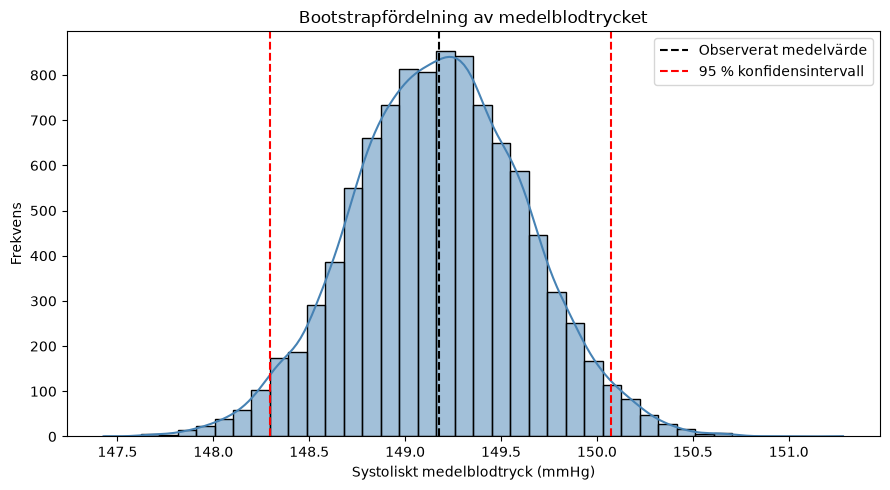

In [19]:
plt.figure(figsize=(9, 5))

sns.histplot(
    bootstrap_means,
    bins=40,
    kde=True,
    color="steelblue"
)

plt.axvline(
    mean_bp,
    color="black",
    linestyle="--",
    label="Observerat medelvärde"
)

plt.axvline(
    ci_bootstrap_lower,
    color="red",
    linestyle="--",
    label="95 % konfidensintervall"
)

plt.axvline(
    ci_bootstrap_upper,
    color="red",
    linestyle="--"
)

plt.title("Bootstrapfördelning av medelblodtrycket")
plt.xlabel("Systoliskt medelblodtryck (mmHg)")
plt.ylabel("Frekvens")
plt.legend()
plt.tight_layout()
plt.show()


**Figur 5.** Fördelning av 10 000 bootstrapmedelvärden.
Den svarta linjen markerar det observerade medelvärdet
och de röda linjerna anger konfidensintervallets gränser.


### 6.3 Jämförelse av konfidensintervallen

För att undersöka hur metodvalet påverkar
konfidensintervallet jämförs intervallgränserna
och intervallens bredd.


In [20]:
# Skapa jämförelsetabell

ci_comparison = pd.DataFrame({
    "Metod": [
        "Normalapproximation",
        "Bootstrap"
    ],
    "Nedre gräns": [
        ci_normal_lower,
        ci_bootstrap_lower
    ],
    "Övre gräns": [
        ci_normal_upper,
        ci_bootstrap_upper
    ],
    "Intervallbredd": [
        ci_normal_upper - ci_normal_lower,
        ci_bootstrap_upper - ci_bootstrap_lower
    ]
})

ci_comparison.round(3)

,Metod,Nedre gräns,Övre gräns,Intervallbredd
0,Normalapproximation,148.292,150.065,1.773
1,Bootstrap,148.297,150.073,1.776


**Tabell 3.** Jämförelse av 95-procentiga
konfidensintervall för genomsnittligt systoliskt
blodtryck beräknade med normalapproximation
respektive bootstrap. Samtliga värden anges i mmHg.


#### Tolkning och jämförelse av konfidensintervallen


Båda metoderna ger konfidensintervall med en bredd
på cirka 1,77 mmHg. Skillnaden mellan intervallgränserna
är mindre än 0,01 mmHg.

Detta är rimligt med tanke på den stora
stickprovsstorleken och blodtryckets ungefär
symmetriska fördelning.

I detta fall ger bootstrap ingen märkbar förbättring
av skattningens precision. Normalapproximationen är
dessutom mindre beräkningskrävande.

Konfidensnivån på 95 % innebär att metoden vid
upprepade stickprov, under relevanta antaganden,
förväntas ge intervall som innehåller det sanna
populationsmedelvärdet i cirka 95 % av fallen.



### 6.4 Metodreferenser

- [SciPy – Normal distribution](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html)

- [NumPy – Random choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.choice.html)

- [NumPy – Percentile](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html)

- [SciPy – Bootstrap](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html)


## 7. Hypotesprövning

Har rökare högre genomsnittligt systoliskt blodtryck
än icke-rökare?

### 7.1 Formulering av hypoteser

$$
H_0: \mu_R \leq \mu_I
$$

$$
H_1: \mu_R > \mu_I
$$

där $\mu_R$ och $\mu_I$ betecknar populationernas
medelblodtryck för rökare respektive icke-rökare.

Eftersom frågeställningen har en given riktning
används ett ensidigt test. Signifikansnivån sätts
till $\alpha = 0.05$.



### 7.2 Beskrivande statistik för respektive grupp

Deltagarna delas in efter rökvanor. Gruppernas
stickprovsstorlekar, medelvärden, medianer och
standardavvikelser sammanställs i tabell 4.



In [21]:
# Dela upp deltagarna i två grupper

smokers = df.loc[
    df["smoker"] == "Yes", "systolic_bp"
].dropna()

non_smokers = df.loc[
    df["smoker"] == "No", "systolic_bp"
].dropna()

# Beräkna beskrivande statistik för grupperna

group_summary = pd.DataFrame({
    "Grupp": ["Rökare", "Icke-rökare"],
    "Antal": [len(smokers), len(non_smokers)],
    "Medelvärde": [smokers.mean(), non_smokers.mean()],
    "Median": [smokers.median(), non_smokers.median()],
    "Standardavvikelse": [
        smokers.std(ddof=1),
        non_smokers.std(ddof=1)
    ]
})

group_summary.round(2)

,Grupp,Antal,Medelvärde,Median,Standardavvikelse
0,Rökare,213,149.52,149.5,13.27
1,Icke-rökare,587,149.05,149.3,12.63



**Tabell 4.** Beskrivande statistik för systoliskt
blodtryck uppdelat efter rökvanor.

In [22]:
# Beräkna observerad skillnad i medelblodtryck

mean_difference = smokers.mean() - non_smokers.mean()

print(f"Skillnad i medelblodtryck: "
      f"{mean_difference:.2f} mmHg")

Skillnad i medelblodtryck: 0.47 mmHg


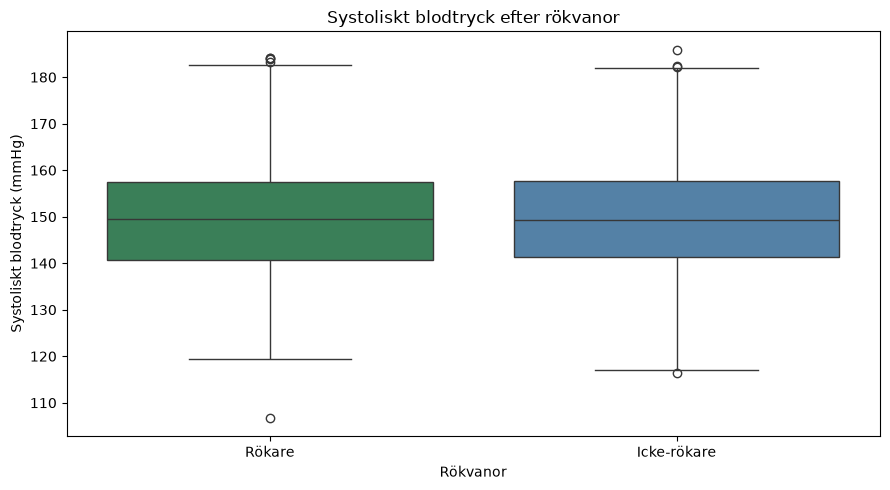

In [23]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="smoker",
    y="systolic_bp",
    order=["Yes", "No"],
    hue="smoker",
    palette=["steelblue", "seagreen"],
    legend=False
)

plt.xticks([0, 1], ["Rökare", "Icke-rökare"])

plt.title("Systoliskt blodtryck efter rökvanor")
plt.xlabel("Rökvanor")
plt.ylabel("Systoliskt blodtryck (mmHg)")

plt.tight_layout()
plt.show()


**Figur 6.** Fördelning av systoliskt blodtryck
bland rökare och icke-rökare.


Visualiseringen möjliggör en inledande jämförelse
mellan gruppernas blodtrycksfördelningar, men ett
statistiskt hypotes­test behövs för att undersöka
om skillnaden i medelvärde är statistiskt signifikant.


### 7.3 Metodval och antaganden

Welchs t-test används eftersom gruppernas
populationsvarianser inte behöver antas vara lika.

Testet förutsätter oberoende observationer inom och
mellan grupperna. Båda grupperna är tillräckligt stora
för att en normalapproximation av stickprovsmedelvärdenas
fördelningar ska vara rimlig enligt centrala gränsvärdessatsen.


Teststatistikan för Welchs t-test beräknas enligt:

$$
t =
\frac{\bar{x}_R-\bar{x}_I}
{\sqrt{\frac{s_R^2}{n_R}+\frac{s_I^2}{n_I}}}
$$

där $\bar{x}$ betecknar stickprovsmedelvärde,
$s^2$ stickprovsvarians och $n$ stickprovsstorlek
för respektive grupp.


### 7.4 Genomförande av hypotesprövningen

Welchs t-test genomförs med `ttest_ind` från SciPy.
Parametern `equal_var=False` innebär att lika
populationsvarianser inte förutsätts.
Med `alternative="greater"` blir testet ensidigt.


In [24]:
# Signifikansnivå

alpha = 0.05

# Ensidigt Welchs t-test

test_result = stats.ttest_ind(
    smokers,
    non_smokers,
    equal_var=False,
    alternative="greater"
)

# Extrahera testresultat

t_statistic = test_result.statistic
p_value = test_result.pvalue

# Presentera resultat

print(f"Skillnad i medelvärde: {mean_difference:.2f} mmHg")
print(f"Teststatistika: {t_statistic:.4f}")
print(f"Frihetsgrader: {test_result.df:.2f}")
print(f"P-värde: {p_value:.6g}")
print(f"Signifikansnivå: {alpha}")

# Statistiskt beslut

if p_value < alpha:
    print("Beslut: Nollhypotesen förkastas.")
else:
    print("Beslut: Nollhypotesen kan inte förkastas.")

Skillnad i medelvärde: 0.47 mmHg
Teststatistika: 0.4503
Frihetsgrader: 360.15
P-värde: 0.326367
Signifikansnivå: 0.05
Beslut: Nollhypotesen kan inte förkastas.



#### Tolkning av hypotesprövningen


Rökarnas genomsnittliga blodtryck är 149,52 mmHg,
jämfört med 149,05 mmHg för icke-rökarna.

Skillnaden är 0,47 mmHg och p-värdet är 0,3264.
Eftersom p-värdet överstiger 0,05 kan nollhypotesen
inte förkastas.

Det finns alltså inte tillräckligt statistiskt stöd
för att rökare har högre genomsnittligt systoliskt
blodtryck än icke-rökare.

Detta innebär inte att populationsmedelvärdena
nödvändigtvis är lika. Testets förmåga att upptäcka
mindre skillnader undersöks i nästa avsnitt.



### 7.5 Metodreferens

- [SciPy – Independent two-sample t-test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)


## 8. Statistisk styrka (poweranalys)

### 8.1 Introduktion

Statistisk styrka är sannolikheten att förkasta
nollhypotesen när en alternativhypotes är sann.

$$
\text{Power} = 1-\beta
$$

där $\beta$ är sannolikheten för ett typ II-fel.

Med hjälp av en Monte Carlo-simulering undersöks
hur testets statistiska styrka påverkas av storleken
på den verkliga skillnaden i medelblodtryck.



### 8.2 Simuleringsmetod

Två normalfördelade populationer simuleras med
gruppstorlekar och standardavvikelser hämtade
från datasetet.

Icke-rökarnas medelvärde används som utgångspunkt.
Medelvärdet för rökare förskjuts mellan 0 och 6 mmHg.

För varje skillnad genereras 5 000 par av stickprov.
Ett ensidigt Welchs t-test genomförs för varje par.

Power skattas som andelen test där p-värdet
understiger 0,05.

Vid en skillnad på 0 mmHg skattas i stället
testets typ I-felnivå.


In [25]:

rng = np.random.default_rng(42)

n_simulations = 5000
alpha = 0.05

n_smokers = len(smokers)
n_non_smokers = len(non_smokers)

std_smokers = smokers.std(ddof=1)
std_non_smokers = non_smokers.std(ddof=1)

baseline_mean = non_smokers.mean()

# Antagna skillnader i medelblodtryck (mmHg)
effect_sizes = np.arange(0, 7, 1)

power_results = []

for effect in effect_sizes:

    # Varje rad motsvarar ett simulerat stickprov
    simulated_smokers = rng.normal(
        loc=baseline_mean + effect,
        scale=std_smokers,
        size=(n_simulations, n_smokers)
    )

    simulated_non_smokers = rng.normal(
        loc=baseline_mean,
        scale=std_non_smokers,
        size=(n_simulations, n_non_smokers)
    )

    # Ett t-test per rad (axis=1)
    simulated_tests = stats.ttest_ind(
        simulated_smokers,
        simulated_non_smokers,
        axis=1,
        equal_var=False,
        alternative="greater"
    )

    power = np.mean(simulated_tests.pvalue < alpha)
    power_results.append(power)


In [26]:
power_table = pd.DataFrame({
    "Verklig skillnad (mmHg)": effect_sizes,
    "Sannolikhet att förkasta H0": power_results,
    "Sannolikhet (%)": np.array(power_results) * 100
})

power_table.round(3)

,Verklig skillnad (mmHg),Sannolikhet att förkasta H0,Sannolikhet (%)
0,0,0.047,4.70
1,1,0.254,25.42
2,2,0.604,60.44
3,3,0.888,88.84
4,4,0.982,98.16
5,5,0.999,99.86
6,6,1.000,100.00


### 8.3 Resultat av poweranalysen

**Tabell 5.** Skattad sannolikhet att förkasta
nollhypotesen vid olika antagna skillnader i
populationernas genomsnittliga systoliska blodtryck.

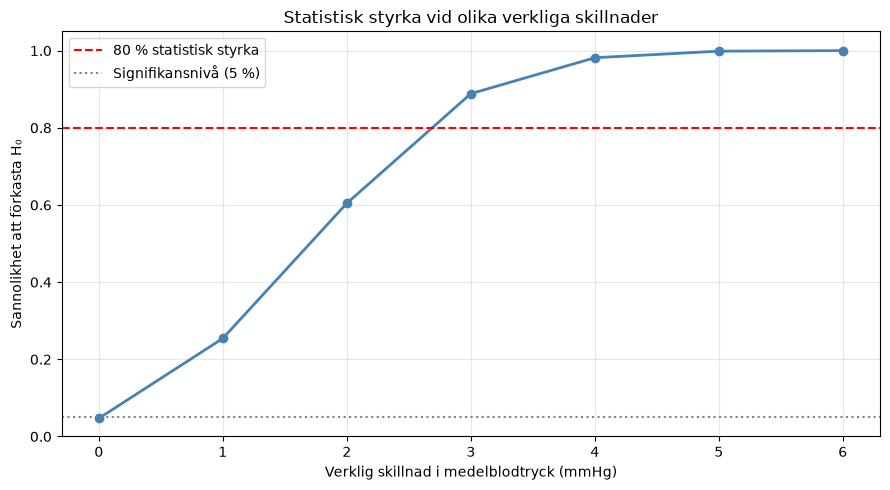

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(
    effect_sizes,
    power_results,
    marker="o",
    color="steelblue",
    linewidth=2
)

plt.axhline(
    0.80,
    color="red",
    linestyle="--",
    label="80 % statistisk styrka"
)

plt.axhline(
    0.05,
    color="gray",
    linestyle=":",
    label="Signifikansnivå (5 %)"
)

plt.title("Statistisk styrka vid olika verkliga skillnader")
plt.xlabel("Verklig skillnad i medelblodtryck (mmHg)")
plt.ylabel("Sannolikhet att förkasta H₀")

plt.ylim(0, 1.05)
plt.xticks(effect_sizes)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


**Figur 7.** Skattad sannolikhet att förkasta
nollhypotesen vid olika skillnader i medelblodtryck.

Den röda linjen markerar referensnivån på 80 %
statistisk styrka och den grå linjen signifikansnivån
på 5 %.



#### Tolkning av poweranalysen

Vid en verklig skillnad på 0 mmHg förkastas
nollhypotesen i 4,70 % av simuleringarna.
Detta ligger nära den valda signifikansnivån på 5 %.

Vid en skillnad på 1 mmHg är power 25,42 % och
vid 2 mmHg är den 60,44 %.

Först vid 3 mmHg överstiger den skattade statistiska
styrkan 80 % bland de undersökta effektstorlekarna.

Testet har alltså god förmåga att upptäcka större
skillnader, medan mindre skillnader är svårare
att upptäcka.

Detta är relevant för hypotesprövningen i avsnitt 7,
där den observerade skillnaden endast var 0,47 mmHg.
Det icke-signifikanta resultatet utesluter inte
en mindre verklig skillnad mellan populationerna.




### 8.4 Metodologiska begränsningar

Resultaten är beroende av antagandet om
normalfördelade populationer samt de skattade
standardavvikelserna och gruppstorlekarna.

Eftersom power skattas med ett begränsat antal
simuleringar finns även en viss Monte Carlo-osäkerhet.
En skattad power på 100 % innebär därför inte att
testet alltid upptäcker den aktuella skillnaden.


### 8.5 Metodreferenser

- [NumPy – Generator.normal](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.normal.html)

- [NumPy – Random Generator](https://numpy.org/doc/stable/reference/random/generator.html)

- [SciPy – Independent two-sample t-test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)


## 9. Sammanfattande slutsats

Analysen omfattar 800 deltagare, varav 5,88 % har
den undersökta sjukdomen.

Det genomsnittliga systoliska blodtrycket är
149,18 mmHg. Normalapproximation och bootstrap
ger i stort sett identiska konfidensintervall.

Hypotesprövningen ger inte tillräckligt statistiskt
stöd för att rökare har högre genomsnittligt
blodtryck än icke-rökare.

Poweranalysen visar dock att testet har begränsad
förmåga att upptäcka små skillnader i medelblodtryck.

### 9.1 Studiens begränsningar

Resultatens generaliserbarhet beror på stickprovets
representativitet.

I jämförelsen mellan rökare och icke-rökare har
hänsyn inte tagits till exempelvis ålder, kön och vikt.

En regressionsanalys skulle kunna användas för att
undersöka sambandet mellan rökning och blodtryck
med hänsyn till dessa variabler.

Några slutsatser om orsakssamband kan inte dras
utifrån den genomförda analysen.

